In [1]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.datasets import make_circles
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)
X, y = make_circles(n_samples=500, factor=0.1, noise=0.35, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [3]:
X.shape

(500, 2)

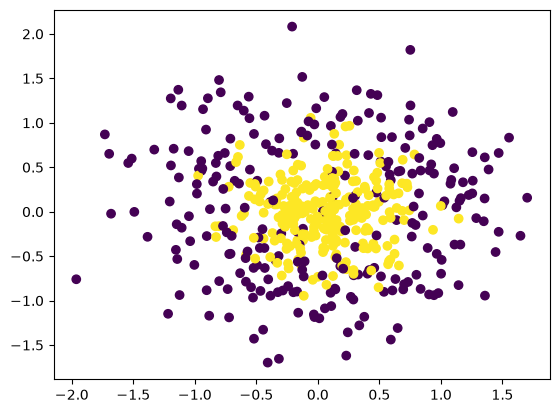

In [4]:
plt.scatter(X[:,0],X[:,1],c=y)

### Compairsation between DT & RF classifier

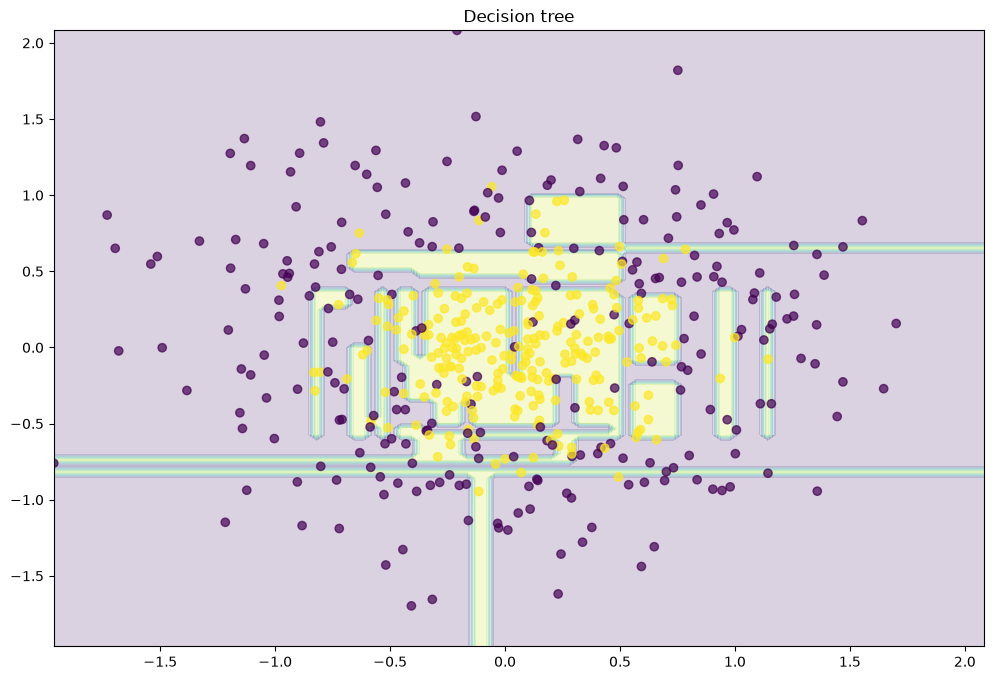

In [5]:
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train, y_train)

plt.figure(figsize=(12, 8))
x_range = np.linspace(X.min(), X.max(), 100)
xx1, xx2 = np.meshgrid(x_range, x_range)
y_hat = dtree.predict(np.c_[xx1.ravel(), xx2.ravel()])
y_hat = y_hat.reshape(xx1.shape)
plt.contourf(xx1, xx2, y_hat, alpha=0.2)
plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=.7)
plt.title("Decision tree")
plt.show()
     

In [25]:
dtree.feature_importances_

array([0.48453771, 0.51546229])

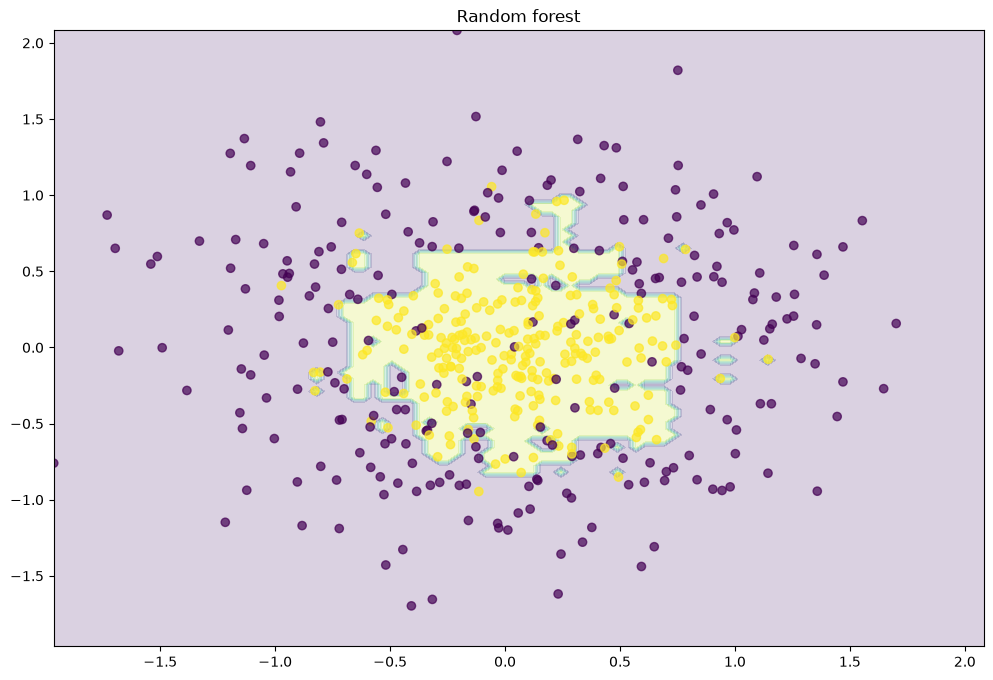

In [6]:
rf = RandomForestClassifier(n_estimators=500, random_state=42)
rf.fit(X_train, y_train)

plt.figure(figsize=(12, 8))
x_range = np.linspace(X.min(), X.max(), 100)
xx1, xx2 = np.meshgrid(x_range, x_range)
y_hat = rf.predict(np.c_[xx1.ravel(), xx2.ravel()])
y_hat = y_hat.reshape(xx1.shape)
plt.contourf(xx1, xx2, y_hat, alpha=0.2)
plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=.7)
plt.title("Random forest")
plt.show()
     

In [26]:
rf.feature_importances_

array([0.09370065, 0.04175828, 0.09368753, 0.06931205, 0.07507807,
       0.01011231, 0.01790418, 0.12776866, 0.06506114, 0.12526077,
       0.04403816, 0.13560786, 0.10071034])

### Conclusion: 
we can see that esaily the DT cls is overfitting (LB,HV) on this dataset and RF is getting more general results (LB,LV)

Feature importance = contribution/importance of each input column in making predictions (higher value is better column for predction).

# OOB_evaluation

In [11]:
from sklearn.metrics import accuracy_score
import pandas as pd

In [13]:
df=pd.read_csv(r'C:\COLLEGE DATA\College profile\Machine Learning\ML_Practice_with_python_code\Datasets\heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [14]:
X=df.iloc[:,0:-1] # all cols start from 0 to till second last
y=df.iloc[:,-1]

In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2, random_state=42)

In [22]:
rf=RandomForestClassifier(oob_score=True)
rf.fit(X_train,y_train)
y_hat=rf.predict(X_test)

In [21]:
rf.oob_score_

0.7892561983471075

In [24]:
rf.estimator_params

('criterion',
 'max_depth',
 'min_samples_split',
 'min_samples_leaf',
 'min_weight_fraction_leaf',
 'max_features',
 'max_leaf_nodes',
 'min_impurity_decrease',
 'random_state',
 'ccp_alpha',
 'monotonic_cst')

In [23]:
print("accuracy_score: ",accuracy_score(y_test,y_hat))

accuracy_score:  0.8524590163934426
